# Model validation of 2D outputs

This notebook showcases some validation procedures using the [modelskill](https://dhi.github.io/modelskill/) package.

Note: this notebook requires the model output data, which can be downloaded from, zenodo.

In [1]:
import mikeio
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd
import glob

In [2]:
ms.options.metrics.list = ["urmse", "mae", "cc", "si", "r2"]

In [3]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "2D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

Model results data are stored in a dfsu file. We can use [MIKE IO](https://dhi.github.io/mikeio) read the data to a MIKE IO Dataset.


In [4]:
ds = mikeio.read(f"{mr_fldr}{mr_fn}", items="*Surf*")
msh = mikeio.open("../input/mesh_EMOD.mesh")
ds.items

[Surface elevation <Surface Elevation> (meter)]

## Compare to measurements

Load water level data from in situ stations

In [5]:
# Water level stations to validate (only the stations with in-situ water level data)
wl_stations = [
    "Drogden", "Klagshamn", "Barseback", "Dragor", "Flinten7",
    "Helsingborg", "Hornbaek", "Kobenhavn", "Koege", "MalmoHamn",
    "Skanor", "Vedbaek", "NordreRose",
]
df_stn = pd.read_csv(obs_fldr + "stations.csv", index_col="Station")

q = ms.Quantity(name="Surface Elevation", unit="meter")
wllist = []
for name in wl_stations:
    row = df_stn.loc[name]
    o = ms.PointObservation(obs_fldr + f"{name}_wl.dfs0", item="water_level", x=row['Longitude'], y=row['Latitude'], name=name, quantity=q)
    wllist.append(o)


Visualize the spatial distribution of stations

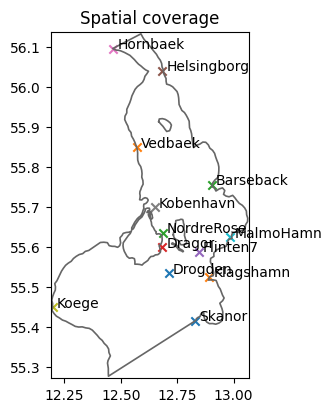

In [6]:
ms.plotting.spatial_overview(wllist, mod=msh,figsize=(3,4.5));
if save_png:
    plt.savefig("../figures/stations.png", bbox_inches="tight")
plt.show()

Create the comparer object using modelskill. This object automatically pairs the observations with the model simulation data using the locations.

In [7]:
cmps = []
da = ds[0]
model_time = pd.DatetimeIndex(ds.time.to_pydatetime())
model_values = da.to_numpy()

for o in wllist:
    # Extract nearest model element and build a point model result
    eid = da.geometry.find_index(coords=(o.x, o.y))[0]
    mser = pd.Series(model_values[:, eid], index=model_time)
    pmr = ms.PointModelResult(mser, x=o.x, y=o.y, name="MIKE3")

    try:
        cmp = ms.match(obs=o, mod=pmr, obs_no_overlap="warn")
        if cmp is not None:
            cmps.append(cmp.remove_bias())
    except Exception as e:
        print(f"{o.name}: {e}")

cc = ms.ComparerCollection(cmps)

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\timeseries\_timeseries.py:412: UserWarning: No data left after trimming to 2022-12-31 23:59:59 - 2025-12-31 23:00:01
  warnings.warn(msg)


<Axes: >

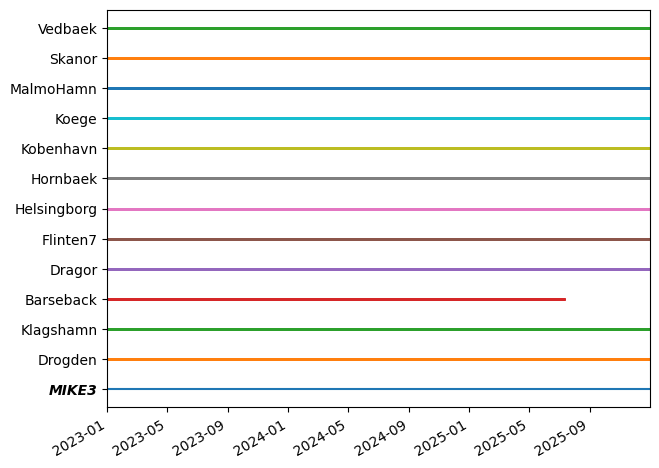

In [8]:
cc.plot.temporal_coverage()

### Skill table

In [9]:
cc.skill().round(3)

,n,urmse,mae,cc,si,r2
observation,,,,,,
Drogden,51509,0.069,0.054,0.940,0.370,0.857
Klagshamn,26264,0.074,0.056,0.945,0.318,0.811
Barseback,21820,0.106,0.070,0.793,0.522,0.608
Dragor,52034,0.070,0.051,0.905,0.366,0.783
Flinten7,25643,0.099,0.069,0.812,0.479,0.502
Helsingborg,25933,0.075,0.055,0.892,0.385,0.793
Hornbaek,51558,0.075,0.058,0.950,0.408,0.885
Kobenhavn,51212,0.115,0.087,0.761,0.563,0.570
Koege,51440,0.074,0.054,0.941,0.369,0.856


### Example timeseries
Plotting the timeseries provides a qualitative assessment of the skill. 

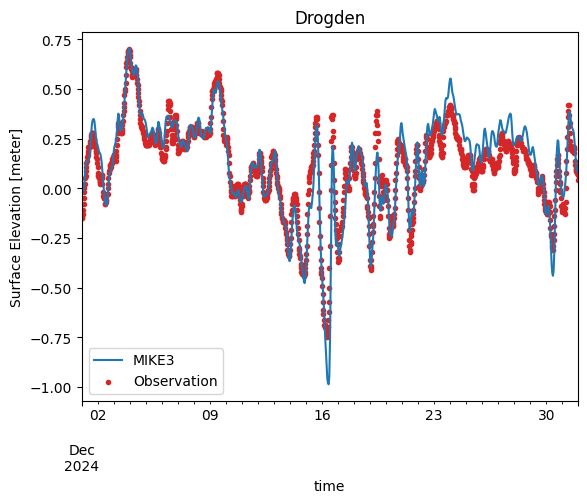

In [10]:
plot_all = False
time_slice = slice("2024-12-01","2024-12-31") if "2024-12-01" in ds.time else None
if not plot_all:
    cc["Drogden"].sel(time=time_slice).plot.timeseries();
else:
    for cmp in cc:
        cmp.sel(time=time_slice).plot.timeseries();
        if save_png:
            plt.savefig(f"{fig_fldr}modelskill_timeseries_{cmp.name}.png", bbox_inches='tight');

### Scatter plots

The scatter plots are saved in the figures folder.

The scatter plots match observations with model predictions. If the fitted line follows the 1:1 line, there is a perfect correspondance between data and model outputs.

In our case, there are some discrepancies, e.g. for the Kobenhavn station. Some of these discrepancies might be due to representation errors, ie. when the model simply is not including dynamics which we know are present, e.g. high-frequency dynamics within a harbor, where the measurement station might be placed.

In [11]:
for cmp in cc:
    cmp.plot.scatter(skill_table=True, figsize=(6,5), bins=40);
    if save_png:
        plt.savefig(f"{fig_fldr}modelskill_comparison_{cmp.name}.png", bbox_inches='tight');
        plt.close()

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000

## Compare to altimetry data
The altimetry data from satellites can also be used for validating the model predictions across a wider range of spatial locations, rather than being limited to the location of the in-situ measurements.

The altimetry data is loaded and registered as a TrackObservation object.

In [12]:
sat_files =sorted(glob.glob(obs_fldr + "Altimetry_wl_*.dfs0"))
missions = [f.split("_")[2].split(".")[0] for f in sat_files]
q = ms.Quantity(name="Surface Elevation", unit="meter")
altlist = []
for m in missions:
    o = ms.TrackObservation(obs_fldr + f"Altimetry_wl_{m}.dfs0", item="water_level", x_item="longitude", y_item="latitude", name=m, quantity=q)
    altlist.append(o)

In [13]:
mr = ms.DfsuModelResult(mr_fldr+mr_fn, name="MIKE3", item=0)
mr

<DfsuModelResult>: MIKE3
Time: 2023-01-01 00:00:00 - 2025-12-31 23:00:00
Quantity: Surface Elevation [m]

A new comparer object is created

In [14]:
cmps = []
match_t = "2025" # You can choose a specific time period here
for o in altlist:
    print(f"Processing {o.name}...")
    try:
        cmp = ms.match(obs=o.sel(time=match_t), mod=mr) 
        cmps.append(cmp.remove_bias())
    except Exception as e:
        print(e)    
cc = ms.ComparerCollection(cmps)

Processing 3a...
Processing 3b...
Processing c2...
Processing j3...
Processing sa...


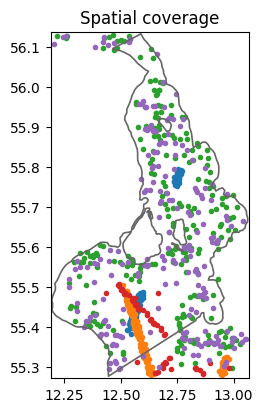

In [15]:
ms.plotting.spatial_overview(altlist, mod=msh,figsize=(3,4.5));
if save_png:
    plt.savefig("../figures/altimetry_coverage.png", bbox_inches="tight")
plt.show()

In [16]:
cc.skill().round(4)

,n,urmse,mae,cc,si,r2
observation,,,,,,
3a,23,0.0684,0.0545,0.9422,0.3146,0.8363
3b,32,0.0593,0.0457,0.9408,0.2802,0.8834
c2,44,0.3513,0.1706,0.5213,0.8381,0.2585
j3,39,0.0801,0.0592,0.9167,0.4863,0.8210
sa,35,0.1494,0.1119,0.6863,0.6056,0.4623


#### Scatter plots

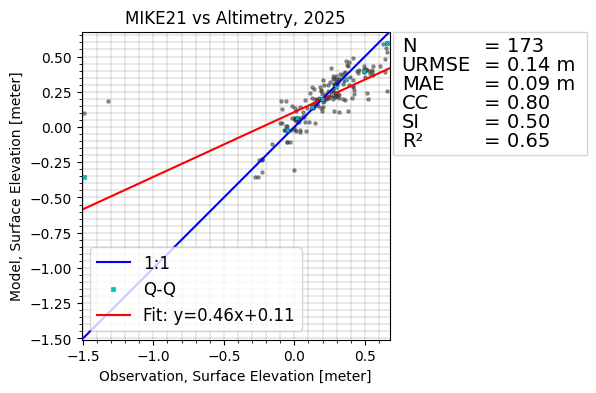

In [17]:
cc.plot.scatter(skill_table=True, figsize=(5,4));
plt.title("MIKE21 vs Altimetry, "+match_t)
if save_png: plt.savefig("../figures/altimetry_comparison.png", bbox_inches="tight")

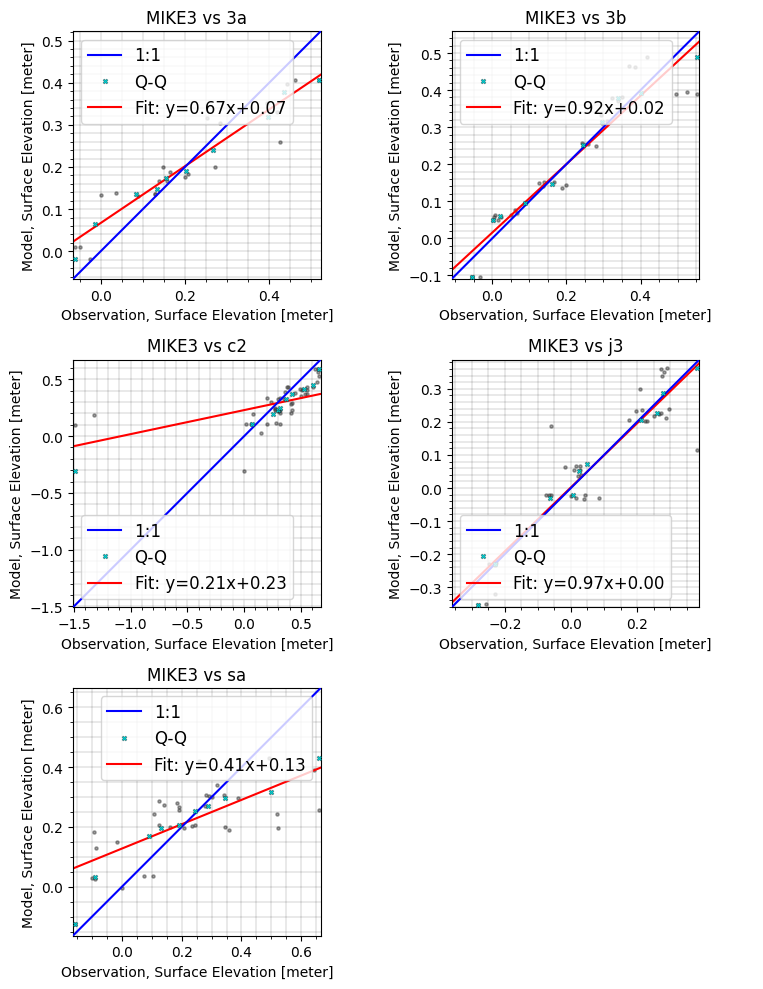

In [18]:
fig, axs = plt.subplots(-(-len(cc)//2), 2, figsize=(8,len(cc)*2))
axs = axs.flatten()
for i in range(len(cc)):
    cc[i].sel().plot.scatter(ax=axs[i])

axs[-1].axis("off")
plt.tight_layout()
plt.show()